## This section focuses on exploring and implementing advanced concepts and techniques in information retrieval and recommender systems. The primary objectives are to develop a semantic search engine using Artificial Neural Networks (ANNs), explore alternative models for text search, and design a recommender system based on lecture transcripts.

## Author: Nam Dang

# Setting up the libraries and environment

In [ ]:
%pip install sentence-transformers annoy pandas scikit-learn

In [ ]:
import pandas as pd
from sentence_transformers import SentenceTransformer

from annoy import AnnoyIndex

In [ ]:
from math import sqrt
from sklearn.metrics import mean_squared_error
from heapq import nlargest

# Semantic Search using ANN for Text-to-Text with Annoy

A pre-trained ANN model can convert each text document into a vector embedding. The model learns the semantic meaning of words from large amounts of text. Documents with similar meanings have similar vector embeddings.

For example, machine learning and artificial intelligence would be close to each other compared to something such as weather forecast

In [ ]:
# Please upload food_recipes.csv file

from google.colab import files

uploaded = files.upload()

Saving food_recipes.csv to food_recipes (1).csv


In [ ]:
recipes = pd.read_csv("food_recipes.csv")

recipes["text"] = recipes["title"] + ". " + recipes["directions"]

model = SentenceTransformer("all-MiniLM-L6-v2")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
print(len(recipes))

50000


In [ ]:
def generate_embeddings(documents):
    embeddings = model.encode(documents)
    return embeddings

embeddings = generate_embeddings(recipes["text"].tolist())

Annoy stores the vector embeddings in an index for fast searching. It uses Approximate Nearest Neighbor to find vectors that are closest to a query vector. This makes semantic search much faster for large datasets.

In [ ]:
# Reference: https://www.kaggle.com/code/aginanjar/analisis-sentimen-dan-information-retrieval

def build_annoy_index(embeddings, num_trees=10):
    dimension = len(embeddings[0])

    index = AnnoyIndex(dimension, "angular")

    for i in range(len(embeddings)):
        index.add_item(i, embeddings[i])

    index.build(num_trees)

    return index


annoy_index = build_annoy_index(embeddings)

First, convert the query text into a vector embedding using the ANN model

Search the Annoy index for the nearest vectors

Return the documents that match those vectors

In [ ]:
def semantic_search(query, num_results):
    query_embedding = model.encode([query])[0]

    indices = annoy_index.get_nns_by_vector(query_embedding, num_results)

    results = recipes.iloc[indices][["title", "directions"]]

    return results

In [ ]:
# Example
semantic_search("chocolate cake", 10)

,title,directions
31801,German Chocolate Cake,Bake cake according to directions on box.
27603,Chocolate Trifle,Bake cake as directed. Break into pieces in tr...
20465,Coconut Cake,Bake cake as box says.
10272,Florence'S Old-Fashioned Chocolate Icing,"Cook this a little longer than\tpreviously, an..."
21424,Jan'S Chocolate Cake,"Just before cake is ready to take out of oven,..."
655,Chocolate Icing,"Mix and boil two minutes., Beat until thick en..."
28225,Chocolate Supreme,"Cake can, be, made, and frozen up to two weeks..."
45127,Death By Chocolate,"Make chocolate cake in a long flat pan., Using..."
22802,Chocolate Zucchini Cake,This makes a very large Bundt cake.
41320,Chocolate Chip Cake,"Preheat oven to 350°., Grease and flour a 10-i..."


Advantages:
- can understand synonyms and find matches even when different words are used
- it is very fast, as we can see from the example above with a dataset of 50000 rows

Limitations:
- needs more CPU/GPU power
- does not always return the exact match

# Searching Images with Text

2 Alternatives for CLIP

1. OpenCLIP:
OpenCLIP is an open-source version of the CLIP model. It can create image and text embeddings, which can be compared using cosine similarity to find the most relevant images for a text query.

Reference: https://sh-tsang.medium.com/brief-review-openclip-reproducible-scaling-laws-for-contrastive-language-image-learning-fe5ed4ea7161

2. BLIP:
BLIP is a vision-language model that can both understand visual information and generate language. It excels at matching images with text for search queries, and can perform tasks such as utomatic image captioning and visual question answering.

Reference: https://www.thakurcoder.com/blog/clip-vs-blip-how-ai-learned-to-connect-pictures-and-words

In [ ]:
!pip install kaggle
!kaggle datasets download -d adityajn105/flickr8k
!unzip -q flickr8k.zip -d flickr8k/

Dataset URL: https://www.kaggle.com/datasets/adityajn105/flickr8k
License(s): CC0-1.0
100% 1.04G/1.04G [00:56<00:00, 19.6MB/s]



In [ ]:
%pip install transformers
%pip install pillow
%pip install open_clip_torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.9 MB/s eta 0:00:00


In [ ]:
import torch
import open_clip
from PIL import Image
import os
import matplotlib.pyplot as plt

# Reference: https://github.com/mlfoundations/open_clip

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768,), eps=1e-05, elementwise_affine

In [ ]:
image_folder = "flickr8k/Images"

image_paths = []

for filename in os.listdir(image_folder):
    if filename.endswith(".jpg"):
        image_paths.append(os.path.join(image_folder, filename))

print(len(image_paths))

8091


In [ ]:
image_features = []

with torch.no_grad():
    for path in image_paths:
        image = preprocess(Image.open(path)).unsqueeze(0).to(device)

        feature = model.encode_image(image)
        feature = feature/feature.norm(dim=-1, keepdim=True)

        image_features.append(feature.cpu())

image_features = torch.cat(image_features)

In [ ]:
def search_images_openclip(query, top_k):

    text = tokenizer([query]).to(device)

    with torch.no_grad():
        text_features = model.encode_text(text)
        text_features = text_features/text_features.norm(dim=-1, keepdim=True)

    similarity = text_features @ image_features.to(device).T

    values, indices = similarity[0].topk(top_k)

    results = []

    for index in indices:
        results.append(image_paths[index])

    return results

flickr8k/Images/3609952704_3719ab0524.jpg
flickr8k/Images/3347701468_bb0001b035.jpg
flickr8k/Images/2983555530_a89f1f5ed7.jpg
flickr8k/Images/2971211296_2587c3924d.jpg
flickr8k/Images/3284887033_e2e48f1863.jpg
flickr8k/Images/3149038044_c7c94688c6.jpg
flickr8k/Images/3494105596_f05cb0d56f.jpg


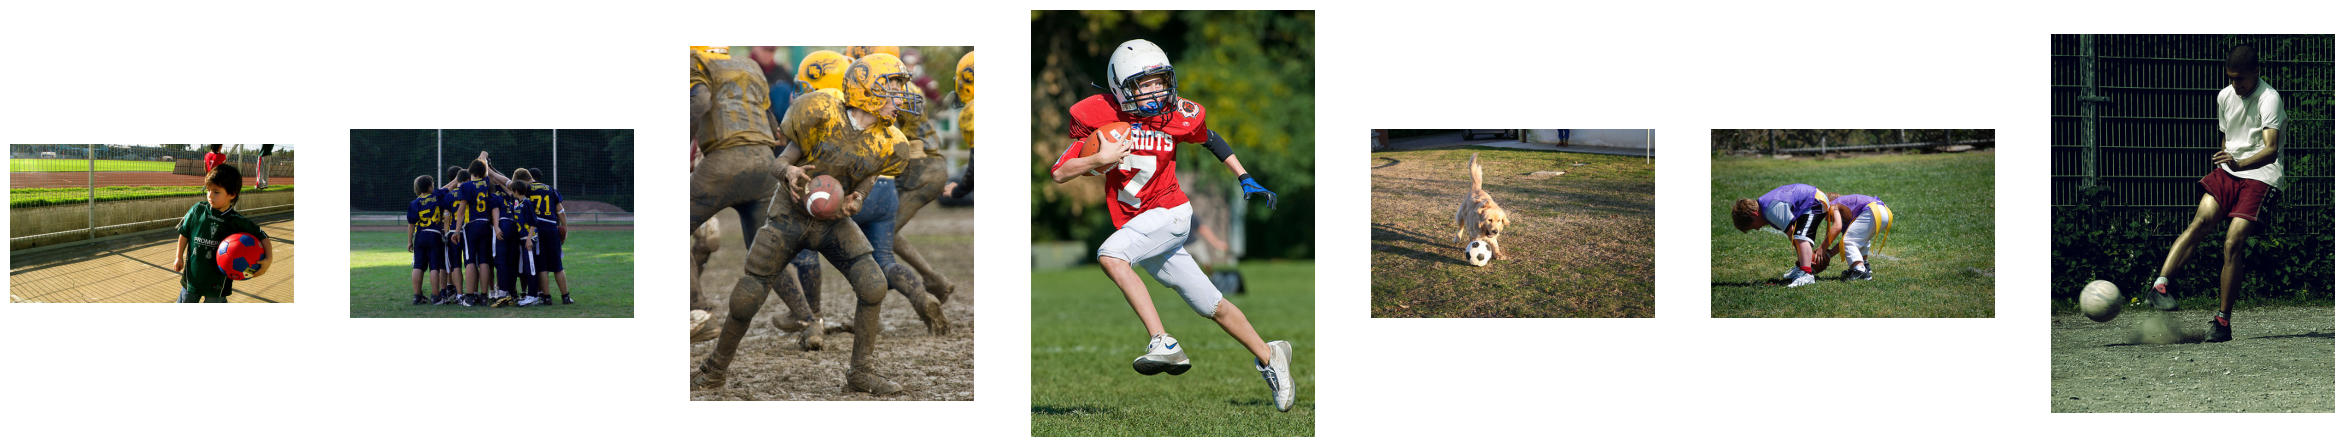

In [ ]:
query = "football"

results = search_images_openclip(query, top_k=7)

for image_path in results:
    print(image_path)


plt.figure(figsize=(30,30))
for i, path in enumerate(results):
    plt.subplot(1, 7, i + 1)
    plt.imshow(Image.open(path))
    plt.axis("off")

plt.show()

Analysis:
- Both CLIP and OpenCLIP can retrieve images based on text descriptions. In this case, it's "football"
- OpenCLIP produced similar results to CLIP

CLIP strength: Dynamic Action Mapping
- has close-up images of human or animal interaction with the ball
- the images seem to have more motions and more dynamic

CLIP weakness: Less Variety
- seems to understand "football" as "soccer", rather than "american football". That is why there is more soccer image.


OpenCLIP strength: Action and Context Variation
- retrieves a diversed set of images with different motions such as holding the ball, running, and kicking
- also has wide shots instead of close-ups, such as image 1 and 2.
- has a variety of images as it also show a football team celebrating instead of just showing player with a ball

OpenCLIP weakness: Ambiguity
- seems to favor human interaction with the ball compared to animal as there is only 1 out of 7 images that has a dog in it
- mixes american football and soccer. It can not lock onto a single sport

# Recommender System

In [ ]:
# Reference: https://www.kaggle.com/datasets/marinagrabelli/ml-100k?select=README

!pip install kaggle
!kaggle datasets download -d marinagrabelli/ml-100k
!unzip -q ml-100k.zip -d ml-100k/

Dataset URL: https://www.kaggle.com/datasets/marinagrabelli/ml-100k
License(s): CC0-1.0
100% 4.77M/4.77M [00:01<00:00, 3.71MB/s]



In [ ]:
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
columns = ["movie_id", "title", "release_date", "video_release_date", "imdb_url", "unknown",
           "Action", "Adventure", "Animation", "Children", "Comedy", "Crime",
           "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery",
           "Romance", "Sci-Fi", "Thriller", "War", "Western"]

movies = pd.read_csv("ml-100k/u.item", sep="|", encoding="latin-1", names=columns)

movies.head()

,movie_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Item-Item Recommender System

1. Data Preprocessing:
Combine movie title and genre

2. Vectorization:
The combined movie title and genre are converted into numerical vectors using TF-IDF

3. Similarity:
Cosine similarity compare movies and create an item similarity matrix

4. Recommendation Generation:
For a selected movie, the system finds the most similar movies based on the combined title and gnere. Then, it recommends them to users

This system recommends movies based on similarity between them instead of user ratings.

In [ ]:
# Reference: https://github.com/khanhnamle1994/movielens/blob/master/Content_Based_and_Collaborative_Filtering_Models.ipynb

def preprocess_items(data):

    item_data = data.copy()

    genres = ["unknown", "Action", "Adventure", "Animation", "Children", "Comedy", "Crime",
              "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery",
              "Romance", "Sci-Fi", "Thriller", "War", "Western"]

    item_data["features"] = ""

    for index, row in item_data.iterrows():

        selected_genres = []

        for genre in genres:
            if row[genre] == 1:
                selected_genres.append(genre)

        item_data.loc[index, "features"] = (row["title"] + " " + " ".join(selected_genres))

    vectorizer = TfidfVectorizer(stop_words="english")

    item_vectors = vectorizer.fit_transform(item_data["features"])

    return item_data, item_vectors

In [ ]:
processed_movies, movie_vectors = preprocess_items(movies)

print(movie_vectors.shape)

(1682, 2301)


In [ ]:
def compute_similarity_matrix(item_vectors):

    similarity_matrix = cosine_similarity(
        item_vectors
    )

    return similarity_matrix

In [ ]:
similarity_matrix = compute_similarity_matrix(
    movie_vectors
)

print(similarity_matrix.shape)

(1682, 1682)


In [ ]:
# Reference: https://www.kaggle.com/code/youngdaniel/recommending-books

def recommend_movies(movie_title, movies, similarity_matrix, top_k=5):

    index = movies[movies["title"] == movie_title].index[0]

    similarity_scores = list(enumerate(similarity_matrix[index]))

    similarity_scores = sorted(similarity_scores, key=lambda x: x[1], reverse=True)

    recommendations = []

    for i, score in similarity_scores[1:top_k+1]:
        recommendations.append((movies.iloc[i]["title"], f'{score:.4f}'))

    return recommendations

In [ ]:
recommend_movies("Aladdin (1992)", processed_movies, similarity_matrix, 10)

[('Aladdin and the King of Thieves (1996)', '0.5897'),
 ('Hercules (1997)', '0.4284'),
 ('Anastasia (1997)', '0.4196'),
 ('Pocahontas (1995)', '0.4078'),
 ('Dumbo (1941)', '0.3772'),
 ('Fantasia (1940)', '0.3761'),
 ('Cinderella (1950)', '0.3743'),
 ('Lion King, The (1994)', '0.3698'),
 ('Three Caballeros, The (1945)', '0.3670'),
 ('All Dogs Go to Heaven 2 (1996)', '0.3666')]

The recommender system can find movies with similar titles and genres using similarity score.

It uses cosine similarity to measure how similar two movies are. A higher cosine similarity score means the movies are more similar.

Looking at the output above, they are all animated movies, which is similar to Aladdin (1992). However, all the similarity scores are not very high (all below 0.6), which suggests that the movies share some features but are not identical.

Strength:
- simple logic and easy to implement
- does not require user ratings

Weakness:
- uses the combination of movie titles and genres, so it cannot understand user preferences
- movies with similar words may be recommended even if they are not really similar

Potential Improvements:
- combine item similarity with user ratings
- add mroe detailed description for each movie

# Collaborative Filtering

Collaborative filtering works by finding users with similar interest or taste, and then recommends movies that those similar users liked. It does not care about the content of the movies, but only who liked them.

Content-based filtering works by finding other movies with similar characteristics from the one a user choose, then recommends them to that user. It only cares about a movie's features instead of replying on users' opinions.

In [ ]:
def dataPreprocessor(rating_df, num_users, num_items):
    """
        INPUT:
            data: pandas DataFrame. columns=['userID', 'itemID', 'rating' ...]
            num_row: int. number of users
            num_col: int. number of items

        OUTPUT:
            matrix: 2D numpy array.

        NOTE 1: see where something very similar is done in the lab in function 'buildUserItemMatrix'

        NOTE 2: data can have more columns, but your function should ignore
              additional columns.
    """
    
    matrix = np.zeros((num_users, num_items))
    for (index, userID, itemID, rating, timestamp) in rating_df.itertuples():
        matrix[userID-1, itemID-1] = rating

    return matrix

Steps:
- initialize an empty matrix
- go through each rating in rating_df. For each rating, identify the userID, itemID, and rating value
- place each rating value into the corresponding cell in the matrix. For example, if User 1 rated Item 10 with a score of 5, then that 5 will go into a cell at matrix[0, 9]

In [ ]:
class BaseLineRecSys(object):
    def __init__(self, method, processor=dataPreprocessor):
        """
            method: string. From ['popularity','useraverage']
            processor: function name. dataPreprocessor by default
        """
        self.method_name = method
        self.method = self._getMethod(self.method_name)
        self.processor = processor
        self.pred_column_name = self.method_name

    def _getMethod(self, method_name):
        """
            Don't change this
        """
        switcher = {
            'popularity': self.popularity,
            'useraverage': self.useraverage,
        }

        return switcher[method_name]

    @staticmethod
    def useraverage(train_matrix, num_users, num_items):
        """
            INPUT:
                train_matrix: 2D numpy array.
                num_users: int. Number of Users.
                num_items: int. Number of Items.
            OUTPUT:
                predictionMatrix: 2D numpy array.

            NOTE: see where something very similar is done in the lab in function 'predictByUserAverage'
        """

        predictionMatrix = np.zeros((num_users, num_items))

        # Initialize the predicted rating matrix with zeros

        for (user, item), rating in np.ndenumerate(train_matrix):

          if rating == 0:
              userVector = train_matrix[user, :]
              ratedItems = userVector[userVector.nonzero()]

              if ratedItems.size == 0:
                  itemAvg = 0
              else:
                  itemAvg = ratedItems.mean()
              predictionMatrix[user, item] = itemAvg
          else:
              predictionMatrix[user, item] = rating

        return predictionMatrix

    @staticmethod
    def popularity(train_matrix, num_users, num_items):
        """
            INPUT:
                train_matrix: 2D numpy array.
                num_users: int. Number of Users.
                num_items: int. Number of Items.
            OUTPUT:
                predictionMatrix: 2D numpy array.

            NOTE: see where something very similar is done in the lab in function 'predictByPopularity'
        """

        predictionMatrix = np.zeros((num_users, num_items))

        # Initialize the predicted rating matrix with zeros

        vf = np.vectorize(lambda x: 1 if x >= 4 else 0)

        itemPopularity = np.zeros(num_items)

        for item in range(num_items):
            numOfUsersRated = len(train_matrix[:, item].nonzero()[0])
            numOfUsersLiked = len(vf(train_matrix[:, item]).nonzero()[0])

            if numOfUsersRated == 0:
                itemPopularity[item] = 0
            else:
                itemPopularity[item] = numOfUsersLiked/numOfUsersRated

        for (user, item), rating in np.ndenumerate(train_matrix):
            if rating == 0:
                predictionMatrix[user, item] = itemPopularity[item]

        return predictionMatrix

    def predict_all(self, train_df, num_users, num_items):

        train_matrix = self.processor(train_df, num_users, num_items)
        self.__model = self.method(train_matrix, num_users, num_items)

    def evaluate_test(self, test_df, copy=False):

        if copy:
            prediction = test_df.copy()
        else:
            prediction = test_df

        prediction[self.pred_column_name] = np.nan

        for (index,
             userID,
             itemID) in tqdm(prediction[['userID','itemID']].itertuples()):
            prediction.loc[index, self.pred_column_name] = self.__model[userID-1, itemID-1]

        return prediction

    def getModel(self):
        """
            return predicted user-item matrix
        """
        return self.__model

    def getPredColName(self):
        """
            return prediction column name
        """
        return self.pred_column_name

    def reset(self):
        """
            reuse the instance of the class by removing model
        """
        try:
            self.model = None
        except:
            print("You don not have model..")


useraverage: predicts what a user might rate an movie that they have not rated. It calculates the average of all the ratings that user has given to other movies they have seen. If a user has not rated any movies, it assumes a default average of zero.

popularity: predicts ratings based on how popular a movie is. For each movie, it calculates a popularity score by checking how many users rated it highly (greater than or equal to 4) compared to the total number of users who rated it. When a user has not seen a movie then its predicted rating is the popularity score.

In [ ]:
fields = ['userID', 'itemID', 'rating', 'timestamp']
ratingDF = pd.read_csv(os.path.join("ml-100k/", 'u.data'), sep='\t', names=fields)

ratingDF.head()

,userID,itemID,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [ ]:
numUsers = len(ratingDF.userID.unique())
numItems = len(ratingDF.itemID.unique())

print("Number of users:", numUsers)
print("Number of items:", numItems)

Number of users: 943
Number of items: 1682


In [ ]:
trainDF = pd.read_csv(os.path.join("ml-100k/", 'u1.base'), sep='\t', names=fields)
testDF = pd.read_csv(os.path.join("ml-100k/", 'u1.test'), sep='\t', names=fields)

print("# of lines in train:", trainDF.shape[0])
print("# of lines in test:", testDF.shape[0])

# of lines in train: 80000
# of lines in test: 20000


In [ ]:
trainUserItemMatrix = dataPreprocessor(trainDF, numUsers, numItems)
testUserItemMatrix = dataPreprocessor(testDF, numUsers, numItems)

In [ ]:
def rmse(pred, test):
    predItems = pred[test.nonzero()].flatten()

    testItems = test[test.nonzero()].flatten()

    return sqrt(mean_squared_error(predItems, testItems))

In [ ]:
def userTopK(prediction, moviesDataset, userID, k):
    userVector = prediction[userID+1,:]

    topK = nlargest(k, range(len(userVector)), userVector.take)

    namesTopK = list(map(lambda x: moviesDataset[moviesDataset.movie_id == x+1]["title"].values[0], topK))

    return namesTopK

In [ ]:
userAvgModel = BaseLineRecSys("useraverage")
userAvgModel.predict_all(trainDF, numUsers, numItems)

userPrediction = userAvgModel.getModel()

userTopK(userPrediction, movies, 7, 10)

['Star Wars (1977)',
 'Evil Dead II (1987)',
 'Bridges of Madison County, The (1995)',
 'True Lies (1994)',
 'Casablanca (1942)',
 'Toy Story (1995)',
 'GoldenEye (1995)',
 'Four Rooms (1995)',
 'Get Shorty (1995)',
 'Copycat (1995)']

In [ ]:
userRMSE = rmse(userPrediction, testUserItemMatrix)
print("User Average RMSE:", userRMSE)

User Average RMSE: 1.0629951276561334


In [ ]:
popModel = BaseLineRecSys("popularity")
popModel.predict_all(trainDF, numUsers, numItems)

popPrediction = popModel.getModel()

userTopK(popPrediction, movies, 7, 10)

['Loch Ness (1995)',
 'Perfect Candidate, A (1996)',
 'Love and Death on Long Island (1997)',
 'Crossfire (1947)',
 'Celestial Clockwork (1994)',
 'They Made Me a Criminal (1939)',
 'Last Time I Saw Paris, The (1954)',
 'Innocents, The (1961)',
 "Jupiter's Wife (1994)",
 'Prefontaine (1997)']

In [ ]:
popRMSE = rmse(popPrediction, testUserItemMatrix)
print("Popularity RMSE:", popRMSE)

Popularity RMSE: 3.177941281084362


- The user average recommender has an RMSE of about 1, which means its predictions are much closer to the actual ratings. It performs better because it considers the user's rating behavior.

- The popularity recommender has an RMSE of about 3, which means its rating predictions have larger errors. This shows that using only popularity does not accurately reflect individual user preferences.

- Based on the output above, the user average recommender suggested blockbuster such as Star Wars and Toy Story. It reveals that the user is a big fan of these genres and gave them high ratings.

- Based on the output above, the popularity recommender suggested mostly less well-known movies. These appears because only a few people watched them, but many who did gave them a good rating.

User-based:
- Strength: This method respects the user's personal taste by looking at how they usually rate things. By this, the user can be seen as a harsh or easy user. This method then avoids suggesting items that do not match the user's rating patterns
- Weakness: If the user has not rated anything, then the system has no data to calculate the average rating, and cannot recommend anything.

Item-based:
- Strength: This method can recommend many items to a new user because it relies on all users' data. The system will also suggest items that are generally liked by everyone
- Weakness: The system will simply recommend an item because they are popular, which might not be the type that a user likes. Popular items get many recommendations and become more popular, while hidden gems will be ignored.  
